# Does any model *generate* the $\rho$ distribution? Per brain area → `figure_ks_stats_{AREA}.pdf`

[`../figure_4/figure_ks_stats.ipynb`](../figure_4/figure_ks_stats.ipynb), once per recording
area instead of pooled.

The question is not which model fits best but whether a model, taken as the truth, would
**produce the distribution of $\rho$ that was measured**. For every neuron and every
candidate model, spikes are simulated from that neuron's own fitted parameters, the
relational-bias model is refit to the synthetic trials, and the resulting $\rho$ values are
pooled into a synthetic distribution. The figure overlays each model's synthetic ECDF on the
real one; the widest vertical gap between them is that model's KS statistic.

The relational-bias curve is the **noise floor**, not a result: it is the model refit to data
simulated from itself, so it shows how much the estimator alone spreads $\rho$ out. Every
other model should be read against it.

**Nothing is re-simulated here.** The synthetic-alpha cache is keyed per (neuron, model,
replicate) with a fingerprint of the fitted parameters, so an area subset reuses exactly the
rows already computed for the pooled figure. The run prints what it reused.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import common
import fit_lib
import ks_lib
import relationality_lib as rl

common.set_style()

# The comparison this figure makes, in figure order — the same set and order as
# `../figure_4/figure_model_comparison.ipynb`, so the supplement and the main figure can be
# read against each other. 'constant' is the reference and is added automatically.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)

# The accents, identical to the main figure: the two leading models get a warm hue each and
# everything else is a light-to-dark grey ramp.
ACCENT, ACCENT_MODEL = '#c1272d', 'future_field'
SECOND_ACCENT, SECOND_ACCENT_MODEL = '#8e3b6b', 'basis_function'      # 'plum'
# This ramp is DARKER than figure_model_comparison.ipynb's 0.82/0.2, and is taken from
# `../figure_4/figure_ks_stats.ipynb` -- the figure this one is the per-area version of.
# These are thin lines on a white panel, and the light end of that ramp does not read as a
# curve.
GRAY_LIGHT, GRAY_DARK = 0.78, 0.12


def model_colors(models=MODELS):
    """One colour per model in `models` order: accents by name, the rest a grey ramp."""
    accents = {ACCENT_MODEL: ACCENT, SECOND_ACCENT_MODEL: SECOND_ACCENT}
    n_grey = sum(m not in accents for m in models)
    greys = iter(np.linspace(GRAY_LIGHT, GRAY_DARK, max(n_grey, 1)))
    return [accents[m] if m in accents else str(next(greys)) for m in models]

CFG = fit_lib.FitConfig()      # the configuration the cache was built with

N_REPS = 5        # synthetic datasets per (neuron, model), all already on disk
SIM_SEED = 0
N_JOBS = 6        # joblib workers. Nothing should recompute — if it does, stop and check
                  #   the cache rather than letting it run.

FIGSIZE = (5.2, 2.9)
XLABEL = 'Relationality (r)'


## Colours and dashes

The two leading models carry a hue each; everything else is grey. Every model curve is dashed,
so it stays distinct from the solid data curve, and the dash lengths separate curves whose
colours are similar. The data curve is the one other colour.

In [2]:
DATA_COLOR = (0.13, 0.62, 0.31)
COLORS = dict(zip(MODELS, model_colors()))

# Dashes separate curves whose colours are close. The two accents are dashed so they stay
# distinct from the solid data curve, and the three greys get the three dash lengths in
# order, so the dash reads as a ramp alongside the grey ramp.
SHORT_DASH, MID_DASH, LONG_DASH = (0.0, (3, 3)), (0.0, (5.0, 3.0)), (0.0, (7.0, 3.0))
STYLES = {'future_field': LONG_DASH, 'basis_function': SHORT_DASH,
          'weighted_average': SHORT_DASH, 'normalization': MID_DASH,
          'inhibition': LONG_DASH}

## The figures

One per area. The KS table below each carries the numbers the curves cannot: the statistic, its bootstrap CI, and the p-value.

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 1339 -> 1339 neurons
FEF: 660 neurons enter the figure
DMFC: 679 neurons enter the figure
--- FEF: real bias median 0.519, 15.0% at 0, 0.5% at 1
31700 rows reused from cache, 0 computed
  dropped 608 cached neuron(s) that are not in this population
16500 synthetic neurons in 5s (cache/figures/figure_4/neuron_models/bias_recovery/8ee5ac260b62dffd)
16500 synthetic neurons


,subject,model,label,n,ks,ks_lo,ks_hi,p,median,frac_at_0,frac_at_1
0,Perle,future_field,Future Field,2025,0.060,0.052,0.104,0.175,0.505,0.127,0.002
1,Perle,basis_function,Basis Func.,2025,0.070,0.052,0.109,0.073,0.533,0.110,0.001
2,Perle,normalization,Normalization,2025,0.490,0.449,0.553,0.000,0.111,0.227,0.000
3,Perle,inhibition,Inhibition,2025,0.538,0.491,0.600,0.000,0.199,0.207,0.000
4,Perle,weighted_average,Weighted Avg.,2025,0.671,0.625,0.721,0.000,0.000,0.514,0.000
5,Elgar,future_field,Future Field,1275,0.054,0.047,0.102,0.550,0.510,0.133,0.002
6,Elgar,basis_function,Basis Func.,1275,0.069,0.067,0.122,0.256,0.458,0.114,0.002
7,Elgar,normalization,Normalization,1275,0.444,0.392,0.506,0.000,0.081,0.260,0.000
8,Elgar,inhibition,Inhibition,1275,0.506,0.443,0.569,0.000,0.207,0.190,0.000
9,Elgar,weighted_average,Weighted Avg.,1275,0.638,0.576,0.698,0.000,0.002,0.494,0.001


saved figure_ks_stats_FEF.pdf


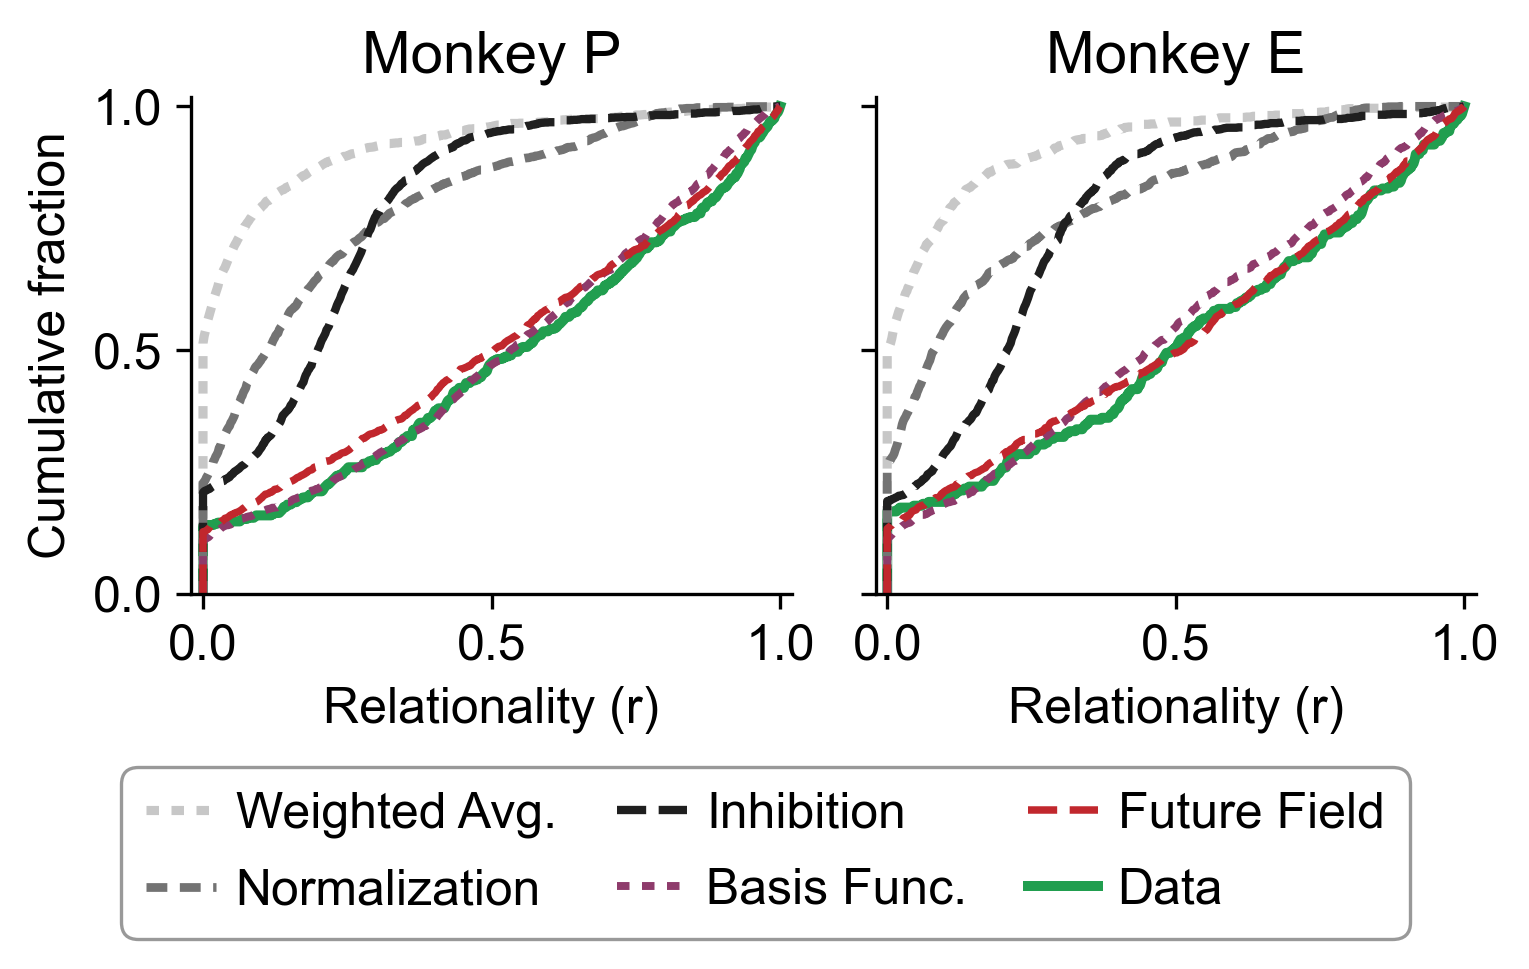

--- DMFC: real bias median 0.731, 12.7% at 0, 0.1% at 1
30000 rows reused from cache, 0 computed
  dropped 521 cached neuron(s) that are not in this population
16975 synthetic neurons in 5s (cache/figures/figure_4/neuron_models/bias_recovery/8ee5ac260b62dffd)
16975 synthetic neurons


,subject,model,label,n,ks,ks_lo,ks_hi,p,median,frac_at_0,frac_at_1
0,Perle,future_field,Future Field,2965,0.047,0.037,0.069,0.230,0.715,0.108,0.003
1,Perle,basis_function,Basis Func.,2965,0.085,0.071,0.121,0.002,0.684,0.096,0.001
2,Perle,normalization,Normalization,2965,0.521,0.496,0.570,0.000,0.194,0.198,0.000
3,Perle,inhibition,Inhibition,2965,0.676,0.636,0.718,0.000,0.218,0.198,0.001
4,Perle,weighted_average,Weighted Avg.,2965,0.758,0.728,0.796,0.000,0.000,0.521,0.000
5,Elgar,future_field,Future Field,430,0.095,0.081,0.198,0.513,0.597,0.140,0.002
6,Elgar,basis_function,Basis Func.,430,0.133,0.093,0.209,0.152,0.616,0.107,0.000
7,Elgar,normalization,Normalization,430,0.528,0.442,0.651,0.000,0.115,0.288,0.000
8,Elgar,inhibition,Inhibition,430,0.619,0.535,0.744,0.000,0.177,0.219,0.000
9,Elgar,weighted_average,Weighted Avg.,430,0.714,0.640,0.849,0.000,0.000,0.560,0.000


saved figure_ks_stats_DMFC.pdf


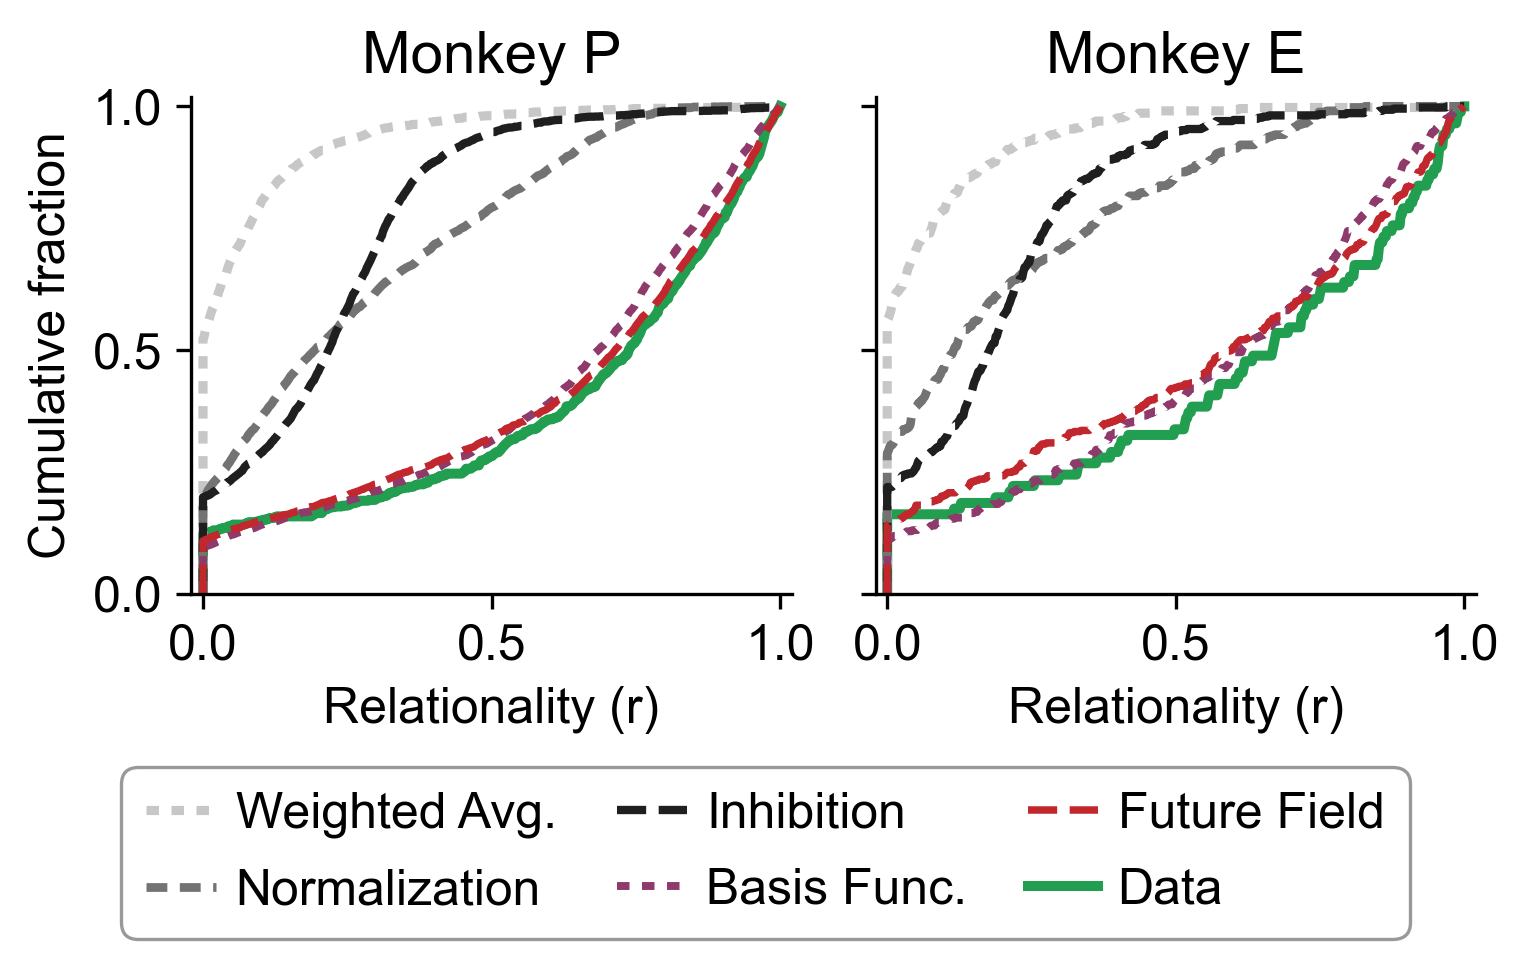

In [3]:
# The metric's own model is the measuring instrument, not one of the models under test, but
# its fitted parameter still has to be in `summary` for `rl.biases` to read — hence the extra
# entry here and nowhere else.
for area, summary in common.selected_fits_by_area(MODELS + (rl.MODEL,)):
    real = rl.biases(summary, verbose=False)
    print(f'--- {area}: real bias median {real["bias"].median():.3f}, '
          f'{(real["bias"] <= 1e-9).mean():.1%} at 0, '
          f'{(real["bias"] >= 1 - 1e-9).mean():.1%} at 1')

    synth = ks_lib.synthetic_biases(summary, MODELS, CFG, n_reps=N_REPS, seed=SIM_SEED,
                                    n_jobs=N_JOBS)
    print(f'{len(synth)} synthetic neurons')
    display(ks_lib.ks_table(real, synth, MODELS, by_subject=True, n_boot=200).round(3))

    fig, axes = ks_lib.plot_bias_ecdf(
        real, synth, MODELS, colors=COLORS, styles=STYLES,
        data_color=DATA_COLOR,
        figsize=FIGSIZE, wspace=0.14,
        xlabel=XLABEL,
        legend_loc='below', legend_bbox=(0.5, 0.13), legend_margin=0.30, legend_ncol=3,
        legend_columnspacing=1.2, legend_borderpad=0.1, legend_labelspacing=0.6,
        legend_handlelength=1.4, legend_handletextpad=0.4, legend_rounding=0.35,
        legend_edgecolor='0.6', legend_lw=0.8,
        lw_step=0.1,)
    common.save(fig, f'figure_ks_stats_{area}.pdf')
    plt.show()